In [1]:
from hcmus.core import appconfig

2025-09-08 20:04:39.307 | INFO     | hcmus.core.appconfig:<module>:7 - Load DotEnv: True


In [2]:
import sys
from loguru import logger
logger.remove()
logger.add(sys.stdout, level="INFO")

1

In [3]:
import os
import json
import clip
import torch
from tqdm import tqdm
from matplotlib import pyplot as plt
from pathlib import Path
from PIL import Image, ImageOps
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.transforms.functional import to_pil_image

In [4]:
class CroppedCocoDataset(Dataset):
    def __init__(self, split_path, transform=None, keep_unknown=False):
        # Get annotation json
        ann_path = None
        for file in os.listdir(split_path):
            if file.startswith("annotations_") and file.endswith(".json"):
                ann_path = os.path.join(split_path, file)
                break
        assert ann_path is not None, "Annotation file not found!"

        with open(ann_path, 'r') as f:
            coco = json.load(f)

        # Build category id to index mapping
        self.cat2idx = {}
        for idx, cat in enumerate(coco['categories']):
            if cat['name'] == "unknown":
                logger.info(f"Skip category_id={cat['id']}")
                continue

            self.cat2idx[cat['id']] = idx

        # Build image id to filename mapping
        self.imgs = {img['id']: img for img in coco['images']}
        self.img_dir = os.path.join(split_path, "images")

        # For each annotation, store (img_file, bbox, label_idx)
        self.samples = []
        self.cache = {}
        for ann in coco['annotations']:
            img_info = self.imgs[ann['image_id']]
            img_file = os.path.join(self.img_dir, img_info['file_name'])
            bbox = ann['bbox']  # [x, y, w, h]
            label_idx = self.cat2idx.get(ann['category_id'])

            if label_idx is not None:
                self.samples.append((img_file, bbox, label_idx))
            elif keep_unknown:
                self.samples.append((img_file, bbox, -1))
            else:
                logger.debug(f"Skip object with category_id={ann['category_id']}")

        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_file, bbox, label_idx = self.samples[idx]
        image = Image.open(img_file).convert("RGB")
        image = ImageOps.exif_transpose(image)

        x, y, w, h = bbox
        x1, y1, x2, y2 = int(x), int(y), int(x + w), int(y + h)
        if idx in self.cache:
            cropped = self.cache.get(idx)
        else:
            cropped = image.crop((x1, y1, x2, y2))
            max_size = 256
            width, height = cropped.size
            scaling_factor = max_size / max(width, height)
            if scaling_factor < 1:
                new_width = int(width * scaling_factor)
                new_height = int(height * scaling_factor)
                cropped = cropped.resize((new_width, new_height), Image.LANCZOS)
            else:
                cropped = cropped

            self.cache[idx] = cropped

        if self.transform:
            cropped = self.transform(cropped)

        return cropped, label_idx

    @property
    def num_classes(self):
        return len(self.cat2idx)


In [5]:
text_metadata = {
  1: "Evian bottled water 500ml",
  2: "Promess sterilized fresh milk whole milk 1L carton",
  3: "Monster Mango Loco energy drink 355ml",
  4: "Safeguard antibacterial hand wash pure white 450ml",
  5: "Sensodyne toothpaste for sensitivity, whitening 100g",
  6: "Colgate Maxfresh toothpaste with bamboo charcoal extract 225g + large-bristle toothbrush",
  7: "Colgate Optic White toothpaste with purple technology 100g",
  8: "Milkis Banana banana-flavored milk soda",
  9: "Korean rice drink 500ml",
  10: "Colgate Maxfresh toothpaste mint flavor 225g + large-bristle toothbrush",
  11: "Colgate Maxfresh toothpaste green tea flavor 225g + large-bristle toothbrush",
  12: "Warrior strawberry energy drink 330ml bottle",
  13: "Redbull energy drink 250ml",
  14: "Winter Melon JJ winter melon tea can 300ml",
  15: "Hao Hao instant noodles spicy shrimp flavor 100g",
  16: "Hao Hao instant noodles with satay and purple onion 75g",
  17: "Hao Hao vegetarian noodles mushroom and vegetable flavor 74g",
  18: "Hao Hao instant noodles spicy shrimp flavor Acecook cup 67g",
  19: "C2 black tea cantaloupe flavor bottle 455ml",
  20: "Pepsi Cola soft drink 320ml",
  21: "Aquafina bottled water 1.5L",
  22: "Sting energy drink red strawberry flavor 330ml",
  23: "Boss milk coffee can 180ml",
  24: "Pepsi no-calorie lemon flavor 320ml",
  25: "Teaplus oolong tea 450ml",
  26: "Vinamilk sterilized fresh milk unsweetened pouch 220ml",
  27: "Vinamilk sterilized fresh milk with sugar, 100% fresh milk 1L",
  28: "Necta Vinamilk peach drink carton 1L",
  29: "Vinacafe 3-in-1 Gold instant milk coffee 480g (24 sachets)",
  30: "Wake Up 247 coffee energy drink 330ml",
  31: "Vinacafe iced milk coffee box 10 sachets 24g",
  32: "1664 Blanc beer 5% ABV bottle 330ml",
  33: "Knorr granulated seasoning pork bone marrow and marrow 900g",
  34: "Maggi soy sauce rich flavor 700ml",
  35: "Maggi soy sauce mild flavor bottle 700ml",
  36: "Nestea instant lemon tea box 195g (15 sachets x 13g)",
  37: "Nescafe 3in1 original instant coffee 782g (17g x 46 sachets)",
  38: "Nestea instant fruit tea box 144g (12 sachets x 12g)",
  39: "Nestea instant lychee and jasmine tea box 144g (12 sachets x 12g)",
  40: "Strongbow Gold Apple cider 4.5% ABV can 320ml",
  41: "Tiger beer tall can 330ml",
  42: "Strongbow Red Berries cider 4.5% ABV can 320ml",
  43: "Heineken Silver beer can 250ml",
  44: "Heineken beer tall can 330ml",
  45: "Heineken non-alcoholic beer can 330ml",
  46: "Tiger Soju Infused Lager Wonder Melon cantaloupe flavor can 330ml",
  47: "Strongbow Pineapple-Pomegranate cider 3.5% can 330ml",
  48: "Tiger Crystal beer 4.6% can 330ml",
  49: "Lemona lemon mineral water bottle 500ml",
  50: "Sunsilk super smooth conditioner 320g",
  51: "Red Lifebuoy hand wash 450ml",
  52: "Green Lifebuoy hand wash Matcha and aloe bottle 450g",
  53: "Sunsilk Natural shampoo anti-hair fall 650g",
  54: "Sunsilk shiny and smooth shampoo bottle 650g",
  55: "Sunsilk super smooth shampoo bottle 650g",
  56: "Blue Lifebuoy hand wash vitamin milk moisturizing refill 1kg",
  57: "Sunlight glass cleaner super fast and clear bottle 520ml",
  58: "Dove Biotin shampoo anti-hair fall 880g",
  59: "Comfort detergent cherry blossom and fresh peach scent bag 3kg",
  60: "Wonderfarm winter melon tea can 310ml",
  61: "Tea Break Milk tea 350ml",
  62: "Lavie bottled water 1.5L",
  63: "Acnes vitamin face wash brightening, fades dark spots 50g",
  64: "Hada Labo deep cleansing oil optimal moisturizing 200ml",
  65: "Pulppy Classic multi-purpose kitchen paper 2-ply, 2 rolls",
  66: "G7 3-in-1 instant milk coffee box 336g (16g x 21 sachets)",
  67: "Trung Nguyen Legend Classic instant coffee box 357g (17g x 21 sachets)",
  68: "Birdy Robusta milk coffee can 170ml",
  69: "Fanta soft drink bottle 1.5L",
  70: "Fuze Tea lemon lemongrass tea 450ml",
  71: "CocaCola original flavor soft drink bottle 600ml",
  72: "CocaCola original flavor soft drink can 320ml",
  73: "Fanta orange flavor soft drink can 320ml",
  74: "Sprite soft drink can 320ml",
  75: "Sprite soft drink bottle 320ml",
  76: "Dasani bottled water 1.5L",
  77: "Nutriboost orange fruit milk bottle 1L",
  78: "Purite shower gel rose scent, softening, bottle 850ml",
  79: "Thai Nguyen green tea 100g",
  80: "Phuc Long green tea bag 2g x box of 25 sachets",
  81: "Cozy peach instant tea box 16 sachets x 15g",
  82: "Cozy lemon instant tea box 240g (16 sachets x 15g)",
  83: "Gift glass cleaner 540ml",
  84: "Hoegaarden Rosee beer bottle 248ml",
  85: "3 Mien instant noodles spicy shrimp flavor 65g",
  86: "3 Mien vegetarian instant noodles pandan leaf 65g (pack)",
  87: "3 Mien Gold beef stew & herbs flavor instant noodles 75g",
  88: "3 Mien chicken pho-style noodles",
  89: "Highland Coffee milk coffee can 185ml",
  90: "Budweiser beer 5% can 330ml",
  91: "Mr.Brown Blue Mountain coffee 240ml",
  92: "TH True Juice Milk blueberry flavored fruit milk drink 300ml",
  93: "Nam Ngu fish sauce 3-in-1 750ml",
  94: "Blue fabric softener super concentrated Spring Scent bag 3.2L",
  95: "Just Viet coconut cappuccino coffee box 10 sachets x 17g",
  96: "Khong Do green tea 500ml",
  97: "Number 1 energy drink bottle 330ml",
  98: "The Coffee House iced milk coffee 22g x 10 sachets (box)",
  99: "TH True Water bottled water 500ml",
  100: "Pocari Sweat ion supply electrolyte drink bottle 900ml",
  101: "Unknown"
}


In [6]:
batch_size = 16

import random

transform_train = T.Compose([
    T.Lambda(lambda img: T.Resize(random.randint(32, 224))(img)),
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(90),
    T.ColorJitter(
        brightness=0.2,
        contrast=0.0,
        saturation=0.0,
        hue=0.0
    ),
    T.RandomCrop((196, 196), padding=10),
    T.ToTensor()
])

transform_test = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

path_to_dataset = Path("/Volumes/Cucumber/Projects/datasets/raw/release-s2m-rp-2025-08-01")
train_dataset = CroppedCocoDataset(path_to_dataset.joinpath("train"), transform=transform_train, keep_unknown=False)
val_dataset = CroppedCocoDataset(path_to_dataset.joinpath("val"), transform=transform_test, keep_unknown=False)

2025-09-08 20:04:40.799 | INFO     | __main__:__init__:18 - Skip category_id=101
2025-09-08 20:04:40.813 | INFO     | __main__:__init__:18 - Skip category_id=101


In [7]:
class CLIPBackbone(nn.Module):
    def __init__(self, text_metadata, model_name="ViT-B/16"):
        super().__init__()
        self.model, self.preprocess = clip.load(model_name, device="cpu")
        self.num_classes = len(text_metadata)
        self.text_keys = text_metadata.keys()
        self.text_embeddings = self.create_text_embedding(text_metadata.values())
        logger.info("Number of classes: {}", self.num_classes)
        self.freeze(self.model)

    def freeze(self, nn):
        for param in nn.parameters():
            param.requires_grad = False

    @property
    def output_dim(self):
        return self.model.visual.output_dim + self.num_classes

    def create_text_embedding(self, texts):
        with torch.no_grad():
            tokenized = clip.tokenize(list(texts))
            txt_feat = self.model.encode_text(tokenized)
        txt_feat = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
        return txt_feat

    def forward(self, image):
        self.model.eval()
        image = self.preprocess(image).unsqueeze(0)

        # Extract features
        with torch.no_grad():
            img_feat = self.model.encode_image(image)     # [1, 512]

        img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
        scores = img_feat @ self.text_embeddings.T
        return torch.concat([img_feat, scores], dim=-1)

class ClassificationHead(nn.Module):
    def __init__(self, backbone, num_classes=100, emb_dim=256):
        super().__init__()
        self.backbone = backbone
        self.fc = nn.Sequential(
            nn.Linear(backbone.output_dim, emb_dim),
            nn.Dropout(0.1),
            nn.ReLU(),
            nn.Linear(emb_dim, num_classes)
        )

    def forward(self, image):
        o = self.backbone(image)
        return self.fc(o)

In [8]:
# backbone = CLIPBackbone(text_metadata)
# classifier = ClassificationHead(backbone, input_dim=backbone.output_dim, num_classes=backbone.num_classes)

In [9]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

def evaluate(model, dataset, prefix="val"):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for image, gt in tqdm(dataset, desc="Evaluating..."):
            image = to_pil_image(image)
            out = model(image)
            all_predictions.append(torch.argmax(out, dim=-1).item())
            all_labels.append(gt)

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    # print(all_predictions, all_labels)

    accuracy = accuracy_score(all_labels, all_predictions)

    # # Micro averages
    precision_micro = precision_score(all_labels, all_predictions, average='micro')
    recall_micro = recall_score(all_labels, all_predictions, average='micro')
    f1_micro = f1_score(all_labels, all_predictions, average='micro')

    # # Macro averages
    precision_macro = precision_score(all_labels, all_predictions, average='macro')
    recall_macro = recall_score(all_labels, all_predictions, average='macro')
    f1_macro = f1_score(all_labels, all_predictions, average='macro')

    metrics = {
        f'{prefix}_accuracy': accuracy,
        f'{prefix}_precision_micro': precision_micro,
        f'{prefix}_recall_micro': recall_micro,
        f'{prefix}_f1_micro': f1_micro,
        f'{prefix}_precision_macro': precision_macro,
        f'{prefix}_recall_macro': recall_macro,
        f'{prefix}_f1_macro': f1_macro
    }
    return metrics

In [10]:
def train_epoch(classifier, dataset, optimizer, criterion, epoch: int):
    mean_loss = 0.0
    desc = "Training (epoch={epoch}, loss={loss:.3f})..."
    bar = tqdm(dataset, desc=desc.format(epoch=epoch, loss=mean_loss))
    for i, (image, gt) in enumerate(bar):
        optimizer.zero_grad()
        image = to_pil_image(image)
        out = classifier(image)
        loss = criterion(out, torch.tensor([gt], dtype=torch.long))
        mean_loss = ((mean_loss * i) + loss.item()) / (i + 1)
        loss.backward()
        optimizer.step()
        bar.set_description(desc.format(epoch=epoch, loss=mean_loss))
    return mean_loss


In [11]:
import mlflow
def save_model(model, filepath):
    """Save the model state dict"""
    torch.save(model.state_dict(), filepath)
    mlflow.log_artifact("model.pt", "model")
    print(f"Model saved to {filepath}")

/Volumes/Cucumber/Projects/item-identification/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [12]:
backbone = CLIPBackbone(text_metadata)
classifier = ClassificationHead(backbone)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(classifier.parameters(), lr=1e-4)

2025-09-08 20:04:44.519 | INFO     | __main__:__init__:8 - Number of classes: 101


In [13]:
import mlflow
mlflow.get_tracking_uri()

'http://jimica.ddns.net:5050'

In [14]:
n_epochs = 256
with mlflow.start_run(experiment_id=8):
    mlflow.log_params({
        "model": "ViT-B/16",
        "embed_dim": classifier.fc[0].out_features,
        "batch_size": batch_size,
        "optimizer": "Adam",
        "n_epochs": n_epochs,
        "lr": 1e-4,
        "criterion": "CrossEntropyLoss"
    })
    best_accuracy = 0
    for epoch in range(n_epochs):
        logger.info(f"Epoch {epoch + 1}/10")
        train_loss = train_epoch(classifier, train_dataset, optimizer, criterion, epoch + 1)
        mlflow.log_metric("train_loss", train_loss, step=epoch + 1)
        if (epoch + 1) % 4 == 0:
            metrics = evaluate(classifier, val_dataset)
            accuracy = metrics["val_accuracy"]
            if accuracy > best_accuracy:
                best_accuracy = accuracy
                save_model(classifier, "model.pt")

            mlflow.log_metrics(metrics, step=epoch + 1)

2025-09-08 20:04:44.796 | INFO     | __main__:<module>:14 - Epoch 1/10


Training (epoch=1, loss=4.535)...:   4%|▍         | 100/2656 [00:11<04:54,  8.69it/s]


🏃 View run fearless-gnat-949 at: http://jimica.ddns.net:5050/#/experiments/8/runs/5bb8c7693eb34783a4687313a34df0aa
🧪 View experiment at: http://jimica.ddns.net:5050/#/experiments/8


KeyboardInterrupt: 

In [ ]:
text_cache = {}
backbone.model.eval()
for k, v in text_metadata.items():
    text = f"a photo of {v}"
    text = clip.tokenize([text])
    with torch.no_grad():
        txt_feat = backbone.model.encode_text(text)       # [1, 512]

    txt_feat = txt_feat / txt_feat.norm(dim=-1, keepdim=True)
    text_cache[k] = txt_feat

In [ ]:
print()

In [ ]:
image, gt = val_dataset[4]
image = to_pil_image(image)

1 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Evian bottled water 500ml
2 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Promess sterilized fresh milk whole milk 1L carton
3 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Monster Mango Loco energy drink 355ml
4 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Safeguard antibacterial hand wash pure white 450ml
5 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Sensodyne toothpaste for sensitivity, whitening 100g
6 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Colgate Maxfresh toothpaste with bamboo charcoal extract 225g + large-bristle toothbrush
7 51 51 torch.return_types.max(
values=tensor([0.3480]),
indices=tensor([51]))
 - Colgate Optic White toothpaste with purple technology 100g
8 51 51 torch.return_types.max(
values=tensor([0.3480]),
in

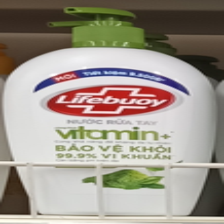

In [ ]:
image, gt = val_dataset[100]
image = to_pil_image(image)
img_feat = backbone.model.encode_image(backbone.preprocess(image).unsqueeze(0))
img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
txt_feats = torch.cat(list(text_cache.values()), dim=0)  # [num_classes, 512]
for k, txt_feat in text_cache.items():
    prediction = classifier(img_feat, txt_feat).max(dim=-1)
    score = prediction.values.item()
    label = prediction.indices.item()
    print(k, gt, label, (img_feat @ txt_feats.T).max(dim=-1))
    print(f" - {text_metadata[k]}")

image